# House Price Prediction Using Linear Regression

## Introduction

House price prediction is an important application of data analytics and machine learning. Property prices are influenced by several factors, including the size of the house, number of rooms, available facilities and furnishing condition.

The objective of this project is to develop a Linear Regression model that predicts house prices based on various housing features.

Using Python and its data science libraries, this project follows an end-to-end machine learning workflow, including data exploration, preprocessing, feature selection, model training, evaluation and interpretation.

The model's performance is evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R-squared (R²).

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
url = "https://github.com/MartinJessenne/Housing-Price-Prediction-Kaggle-Dataset/raw/refs/heads/main/Housing.csv"
df = pd.read_csv(url)

# Initial inspection
print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary of numerical columns
print("\nNumerical Summary:")
display(df.describe())

# Statistical summary of categorical columns
print("\nCategorical Summary:")
display(df.describe(include="object"))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainro

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Categorical Summary:


,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


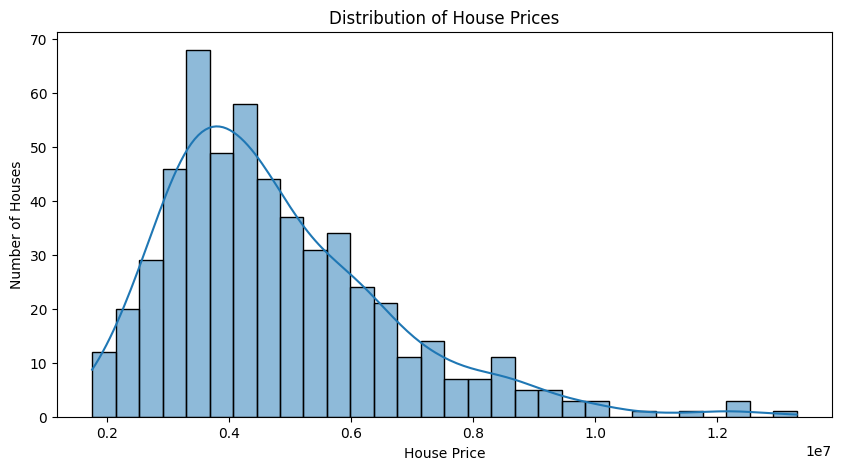

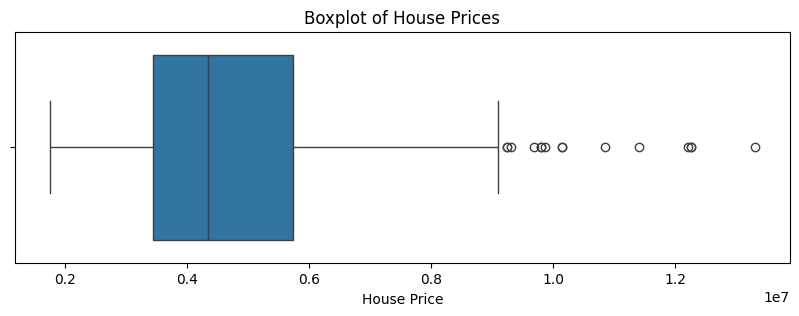

In [3]:
# Distribution of house prices
plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.show()

# Boxplot to identify potential outliers
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["price"])

plt.title("Boxplot of House Prices")
plt.xlabel("House Price")
plt.show()

**Observations:**

- The distribution of house prices is positively (right) skewed, indicating that most houses are concentrated in the lower-to-middle price range.
- Most houses are priced approximately between 3 million and 6 million.
- The median house price is 4.34 million.
- The boxplot identifies several potential high-price outliers above the upper whisker.
- These values may represent expensive properties, so they should not be removed without further investigation.

### Feature Selection

The target variable for this project is `price`. The following features were selected as potential predictors:

- **Area:** Larger houses may have higher prices.
- **Bedrooms and Bathrooms:** The number of rooms can influence property value.
- **Stories:** The number of floors may affect the house price.
- **Parking:** Parking availability can increase property value.
- **Mainroad and Prefarea:** Accessibility and preferred location may influence prices.
- **Guestroom and Basement:** Additional facilities may contribute to property value.
- **Hotwaterheating and Airconditioning:** These amenities may affect buyer preferences.
- **Furnishingstatus:** The furnishing condition may influence the selling price.

These features were selected based on their potential relationship with house prices. The dataset does not contain explicit house-age or detailed geographical-location variables, which limits the factors available for analysis.

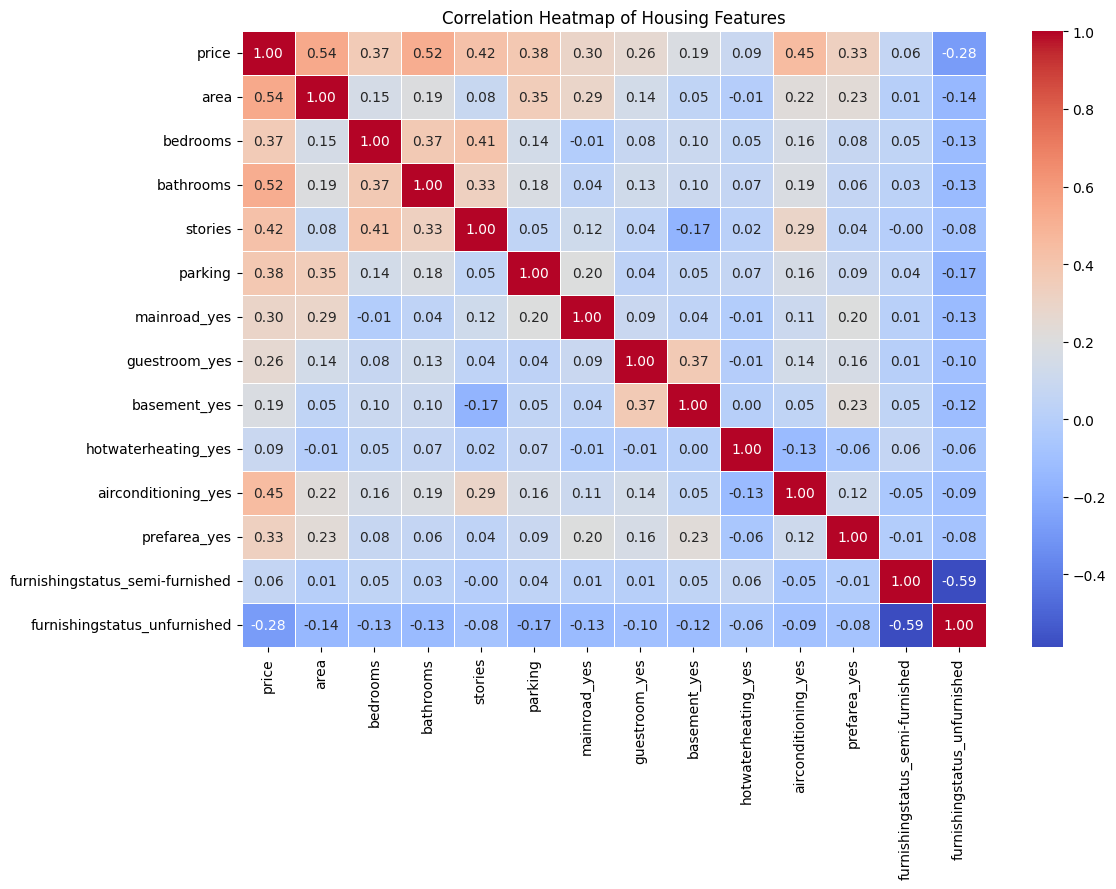

In [4]:
# Convert categorical features into numerical form for correlation analysis
correlation_df = pd.get_dummies(df, drop_first=True, dtype=int)

# Calculate correlation matrix
correlation_matrix = correlation_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Housing Features")
plt.show()

**Correlation Heatmap Observations:**

- Area has the strongest positive correlation with price (0.54), suggesting that larger houses generally have higher prices.
- Bathrooms show a positive correlation of 0.52 with price.
- Airconditioning (0.45) and stories (0.42) also show moderate positive correlations.
- Bedrooms (0.37) and parking (0.38) have positive relationships with price.
- Unfurnished status has a negative correlation with price (-0.28), suggesting that unfurnished houses tend to have lower prices.
- Overall, area, bathrooms, airconditioning and stories show relatively stronger relationships with house prices.

Correlation indicates association, not causation.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Separate features and target
X = df.drop("price", axis=1)
y = df["price"]

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

# Preprocess categorical features using One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (436, 12)
Testing data shape: (109, 12)
Training target shape: (436,)
Testing target shape: (109,)


In [6]:
from sklearn.metrics import mean_squared_error, r2_score

# Create a pipeline with preprocessing and Linear Regression
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

# Predict house prices on test data
y_pred = model.predict(X_test)

# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R²):", round(r2, 4))


Model Evaluation Results
------------------------
Mean Squared Error (MSE): 1754318687330.7
Root Mean Squared Error (RMSE): 1324506.96
R-squared (R²): 0.6529


**Model Evaluation Observations:**

- The Linear Regression model achieved an R² score of 0.6529, indicating that it explains approximately 65.29% of the variation in house prices.
- The RMSE is 1,324,506.96, representing the typical magnitude of prediction errors in the dataset's price units.
- The MSE is 1,754,318,687,330.70, measuring the average squared difference between actual and predicted prices.
- The results indicate that the model captures some important relationships between housing features and prices, although prediction errors remain.

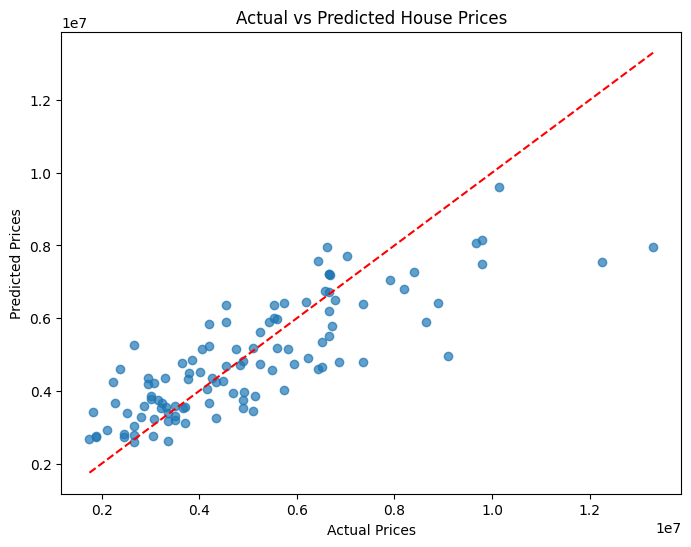

In [7]:
# Compare actual and predicted house prices
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.show()


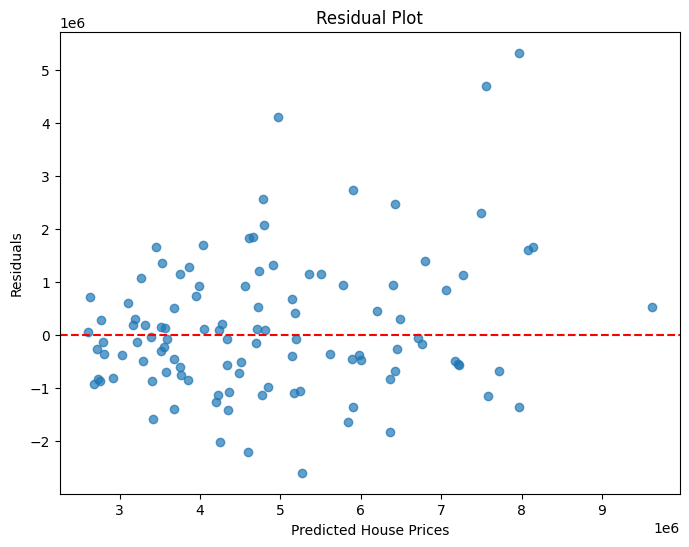

In [8]:
# Calculate residuals
residuals = y_test - y_pred

# Plot residuals
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.show()


**Actual vs Predicted Prices — Observations:**

- The scatter plot compares actual house prices with the prices predicted by the Linear Regression model.
- Points closer to the red diagonal line indicate more accurate predictions.
- Most predictions follow the general trend of actual prices.
- However, the model tends to underestimate some higher-priced houses, indicating reduced accuracy for expensive properties.

**Residual Plot — Observations:**

- Residuals represent the difference between actual and predicted house prices.
- The residuals appear on both sides of the zero reference line.
- The spread of residuals increases at higher predicted prices, suggesting non-constant error variance.
- This indicates that the model's prediction errors are not uniform across all price ranges.

In [9]:
# Extract feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Extract Linear Regression coefficients
coefficients = model.named_steps["regressor"].coef_

# Create a DataFrame of coefficients
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Display top 5 positive coefficients
positive_coefficients = coefficient_df[
    coefficient_df["Coefficient"] > 0
].sort_values(by="Coefficient", ascending=False)

print("Top 5 Positive Coefficients:")
display(positive_coefficients.head(5))

Top 5 Positive Coefficients:


,Feature,Coefficient
10,remainder__bathrooms,1.094445e+06
4,categorical__airconditioning_yes,7.914267e+05
3,categorical__hotwaterheating_yes,6.846499e+05
5,categorical__prefarea_yes,6.298906e+05
11,remainder__stories,4.074766e+05


In [11]:
# Display only negative coefficients
negative_coefficients = coefficient_df[
    coefficient_df["Coefficient"] < 0
].sort_values(by="Coefficient", ascending=True)

print("Negative Coefficients:")
display(negative_coefficients)

Negative Coefficients:


,Feature,Coefficient
7,categorical__furnishingstatus_unfurnished,-413645.062228
6,categorical__furnishingstatus_semi-furnished,-126881.817585


## Conclusion

In this project, a Linear Regression model was developed to predict house prices using numerical and categorical housing features.

The dataset was explored and checked for missing values and duplicate records. Categorical variables were transformed using One-Hot Encoding, and the data was divided into training and testing sets using an 80:20 split.

The model achieved an R² score of **0.6529**, explaining approximately 65.29% of the variation in house prices. The RMSE was **1,324,506.96**, indicating that prediction errors remain significant.

Visualisations and coefficient analysis helped evaluate the model's predictions, identify potential error patterns and understand the relationships between housing features and predicted prices.

Overall, the project demonstrates the application of Linear Regression in a complete machine learning workflow. Although the model provides a useful baseline, incorporating additional features and exploring more advanced algorithms could improve prediction accuracy.